# Projet BankReco
## Étape 2 : Préparation des données bancaires

**Cours :** INF-5103 — Concepts statistiques pour la science des données

**Objectif :** Construire un échantillon longitudinal
de 20 000 clients à partir du jeu de données Santander.

In [6]:
import pandas as pd
import numpy as np
from pathlib import Path

fichier = Path("data/train_ver2.csv.zip")

N_CLIENTS = 20000
TAILLE_BLOC = 100000
GRAINE = 42

print("Fichier disponible :", fichier.exists())

Fichier disponible : True


In [10]:
# Ensemble des identifiants clients
ids_clients = set()

# Lecture progressive du fichier
for bloc in pd.read_csv(
    fichier,
    compression="zip",
    usecols=["ncodpers"],
    chunksize=TAILLE_BLOC
):
    ids_clients.update(
        bloc["ncodpers"].dropna().astype("int64")
    )

# Nombre total de clients
print("Nombre total de clients distincts :", len(ids_clients))

# Générateur aléatoire reproductible
rng = np.random.default_rng(GRAINE)

# Sélection aléatoire de 20 000 clients
clients_selectionnes = rng.choice(
    np.array(sorted(ids_clients), dtype="int64"),
    size=min(N_CLIENTS, len(ids_clients)),
    replace=False
)

clients_selectionnes = set(
    clients_selectionnes.tolist()
)

print("Clients sélectionnés :", len(clients_selectionnes))

Nombre total de clients distincts : 956645
Clients sélectionnés : 20000


In [13]:
# Liste destinée à conserver les blocs sélectionnés
blocs_selectionnes = []

# Lecture progressive du fichier complet
for bloc in pd.read_csv(
    fichier,
    compression="zip",
    chunksize=TAILLE_BLOC,
    low_memory=False
):

    # Conserver uniquement les clients sélectionnés
    selection = bloc[
        bloc["ncodpers"].isin(clients_selectionnes)
    ].copy()

    # Ajouter les observations trouvées
    if not selection.empty:
        blocs_selectionnes.append(selection)

# Regrouper les blocs
df_long = pd.concat(
    blocs_selectionnes,
    ignore_index=True
)

# Convertir les dates
df_long["fecha_dato"] = pd.to_datetime(
    df_long["fecha_dato"]
)

# Trier par client et par date
df_long = df_long.sort_values(
    ["ncodpers", "fecha_dato"]
).reset_index(drop=True)

# Afficher les résultats
print("Dimensions :", df_long.shape)

print(
    "Clients distincts :",
    df_long["ncodpers"].nunique()
)

print(
    "Mois distincts :",
    df_long["fecha_dato"].nunique()
)

Dimensions : (285734, 48)
Clients distincts : 20000
Mois distincts : 17


In [14]:
# Nombre de clients observés chaque mois
clients_par_mois = (
    df_long.groupby("fecha_dato")["ncodpers"]
    .nunique()
    .sort_index()
)

print("Nombre de clients par mois :")
display(clients_par_mois.to_frame("Nombre de clients"))

# Nombre d'observations par client
observations_par_client = (
    df_long.groupby("ncodpers")
    .size()
)

print("\nStatistiques des observations par client :")
display(observations_par_client.describe())

Nombre de clients par mois :


,Nombre de clients
fecha_dato,
2015-01-28,13193
2015-02-28,13217
2015-03-28,13244
2015-04-28,13282
2015-05-28,13305
2015-06-28,13308
2015-07-28,17396
2015-08-28,17617
2015-09-28,18070



Statistiques des observations par client :


count    20000.000000
mean        14.286700
std          4.033028
min          1.000000
25%         11.000000
50%         17.000000
75%         17.000000
max         17.000000
dtype: float64

In [15]:
doublons = df_long.duplicated(
    subset=["ncodpers", "fecha_dato"]
).sum()

print("Nombre de doublons client-date :", doublons)

Nombre de doublons client-date : 0


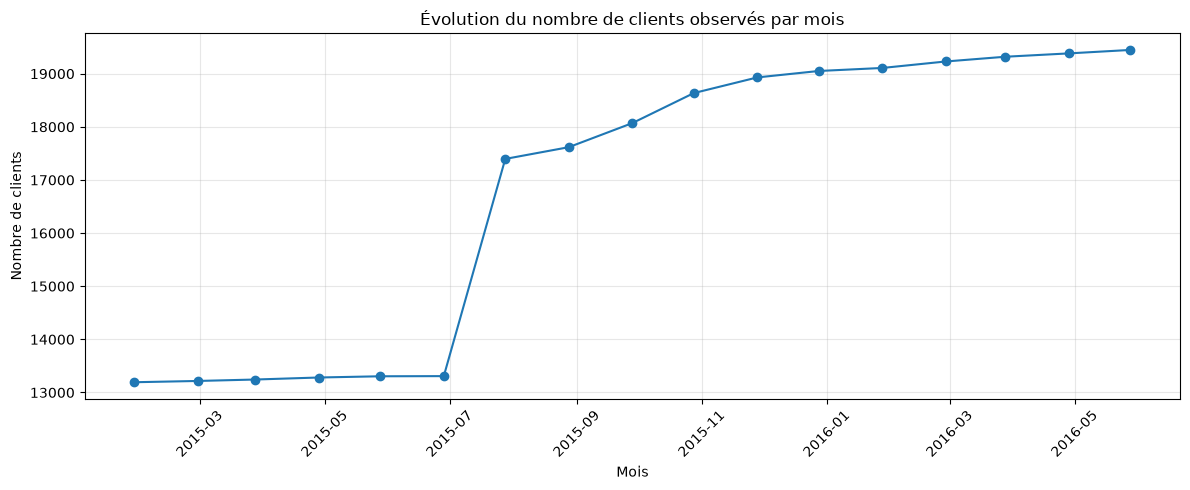

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    clients_par_mois.index,
    clients_par_mois.values,
    marker="o"
)

plt.title("Évolution du nombre de clients observés par mois")
plt.xlabel("Mois")
plt.ylabel("Nombre de clients")
plt.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
from pathlib import Path

sortie = Path("data/santander_echantillon.csv")

df_long.to_csv(
    sortie,
    index=False
)

print("Fichier enregistré :", sortie)
print("Taille en Mo :", round(sortie.stat().st_size / 1024**2, 2))

Fichier enregistré : data\santander_echantillon.csv
Taille en Mo : 46.41


In [18]:
# Copie de travail
df_clean = df_long.copy()

# Identifier les colonnes des produits
produits = [
    col for col in df_clean.columns
    if col.endswith("_ult1")
]

# Convertir les produits en valeurs numériques
df_clean[produits] = df_clean[produits].apply(
    pd.to_numeric,
    errors="coerce"
)

# Vérifier les valeurs présentes
for produit in produits:
    valeurs = df_clean[produit].dropna().unique()
    if not set(valeurs).issubset({0, 1}):
        print("Valeurs inhabituelles :", produit, valeurs)

print("Nombre de produits :", len(produits))
print("Dimensions :", df_clean.shape)

Nombre de produits : 24
Dimensions : (285734, 48)


In [19]:
# Nombre de valeurs manquantes
manquantes = df_clean[produits].isna().sum()

# Pourcentage de valeurs manquantes
taux_manquants = (
    manquantes / len(df_clean) * 100
)

# Tableau récapitulatif
tableau_manquants = pd.DataFrame({
    "Valeurs manquantes": manquantes,
    "Pourcentage (%)": taux_manquants
})

tableau_manquants = tableau_manquants.sort_values(
    "Pourcentage (%)",
    ascending=False
)

display(tableau_manquants)

,Valeurs manquantes,Pourcentage (%)
ind_nom_pens_ult1,369,0.129141
ind_nomina_ult1,369,0.129141
ind_ahor_fin_ult1,0,0.000000
ind_aval_fin_ult1,0,0.000000
ind_cno_fin_ult1,0,0.000000
ind_ctju_fin_ult1,0,0.000000
ind_cco_fin_ult1,0,0.000000
ind_cder_fin_ult1,0,0.000000
ind_ctop_fin_ult1,0,0.000000
ind_ctma_fin_ult1,0,0.000000


In [20]:
# Trier les observations
df_clean = df_clean.sort_values(
    ["ncodpers", "fecha_dato"]
).reset_index(drop=True)

# Identifier le mois précédent pour chaque client
date_precedente = (
    df_clean.groupby("ncodpers")["fecha_dato"]
    .shift(1)
)

# Vérifier que les observations sont sur deux mois consécutifs
mois_actuel = df_clean["fecha_dato"].dt.to_period("M")
mois_precedent = date_precedente.dt.to_period("M")

consecutif = (
    (mois_actuel - 1) == mois_precedent
)

# Produits détenus lors de l'observation précédente
produits_precedents = (
    df_clean.groupby("ncodpers")[produits]
    .shift(1)
)

# Acquisition = absent précédemment et présent maintenant
acquisitions = (
    (produits_precedents == 0)
    & (df_clean[produits] == 1)
).astype("Int64")

# Mettre NA lorsque les deux observations ne sont pas valides
valides = (
    consecutif.to_numpy()[:, None]
    & produits_precedents.notna().to_numpy()
    & df_clean[produits].notna().to_numpy()
)

acquisitions = acquisitions.where(valides)

# Renommer les colonnes
acquisitions.columns = [
    "acq_" + produit for produit in produits
]

print("Dimensions des acquisitions :", acquisitions.shape)

display(acquisitions.head())

Dimensions des acquisitions : (285734, 24)


,acq_ind_ahor_fin_ult1,acq_ind_aval_fin_ult1,acq_ind_cco_fin_ult1,acq_ind_cder_fin_ult1,acq_ind_cno_fin_ult1,acq_ind_ctju_fin_ult1,acq_ind_ctma_fin_ult1,acq_ind_ctop_fin_ult1,acq_ind_ctpp_fin_ult1,acq_ind_deco_fin_ult1,...,acq_ind_hip_fin_ult1,acq_ind_plan_fin_ult1,acq_ind_pres_fin_ult1,acq_ind_reca_fin_ult1,acq_ind_tjcr_fin_ult1,acq_ind_valo_fin_ult1,acq_ind_viv_fin_ult1,acq_ind_nomina_ult1,acq_ind_nom_pens_ult1,acq_ind_recibo_ult1
0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [21]:
# Nombre total d'acquisitions par produit
total_acquisitions = acquisitions.sum().sort_values(
    ascending=False
)

print("Nouvelles acquisitions par produit :")

display(
    total_acquisitions.to_frame(
        "Nombre d'acquisitions"
    )
)

Nouvelles acquisitions par produit :


,Nombre d'acquisitions
acq_ind_recibo_ult1,3350
acq_ind_nom_pens_ult1,1927
acq_ind_nomina_ult1,1691
acq_ind_cco_fin_ult1,1486
acq_ind_tjcr_fin_ult1,1457
acq_ind_cno_fin_ult1,802
acq_ind_ecue_fin_ult1,570
acq_ind_dela_fin_ult1,261
acq_ind_reca_fin_ult1,183
acq_ind_ctma_fin_ult1,139


In [22]:
# selection de 8 produits pertinents
produits_retenus = [
    "ind_recibo_ult1",
    "ind_nom_pens_ult1",
    "ind_nomina_ult1",
    "ind_cco_fin_ult1",
    "ind_tjcr_fin_ult1",
    "ind_cno_fin_ult1",
    "ind_ecue_fin_ult1",
    "ind_dela_fin_ult1"
]

colonnes_acquisitions = [
    "acq_" + p for p in produits_retenus
]

print("Nombre de produits retenus :", len(produits_retenus))

Nombre de produits retenus : 8


In [23]:
# Associer les dates aux acquisitions
acquisitions_mensuelles = acquisitions[
    colonnes_acquisitions
].copy()

acquisitions_mensuelles["fecha_dato"] = (
    df_clean["fecha_dato"].values
)

# Compter les acquisitions par mois
tableau_mensuel = (
    acquisitions_mensuelles
    .groupby("fecha_dato")[colonnes_acquisitions]
    .sum()
)

display(tableau_mensuel)

,acq_ind_recibo_ult1,acq_ind_nom_pens_ult1,acq_ind_nomina_ult1,acq_ind_cco_fin_ult1,acq_ind_tjcr_fin_ult1,acq_ind_cno_fin_ult1,acq_ind_ecue_fin_ult1,acq_ind_dela_fin_ult1
fecha_dato,,,,,,,,
2015-01-28,0,0,0,0,0,0,0,0
2015-02-28,172,126,125,38,92,41,35,18
2015-03-28,207,102,102,60,104,40,37,23
2015-04-28,167,120,56,32,95,37,36,14
2015-05-28,177,87,88,49,92,47,30,24
2015-06-28,200,200,131,151,96,43,27,18
2015-07-28,189,104,94,47,93,58,17,27
2015-08-28,146,65,65,123,86,55,21,16
2015-09-28,253,122,122,96,95,43,22,31


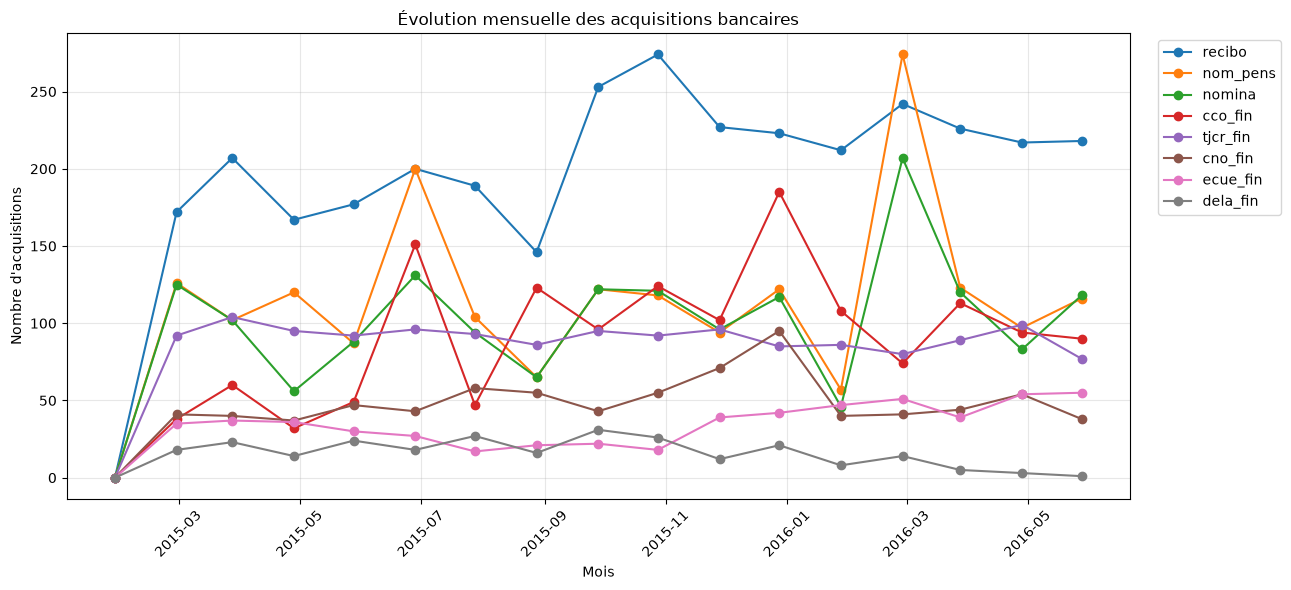

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 6))

for colonne in colonnes_acquisitions:
    plt.plot(
        tableau_mensuel.index,
        tableau_mensuel[colonne],
        marker="o",
        label=colonne.replace("acq_ind_", "").replace("_ult1", "")
    )

plt.title("Évolution mensuelle des acquisitions bancaires")
plt.xlabel("Mois")
plt.ylabel("Nombre d'acquisitions")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
# Définition des périodes
def definir_periode(date):
    if date <= pd.Timestamp("2015-12-28"):
        return "Entrainement"
    elif date <= pd.Timestamp("2016-03-28"):
        return "Validation"
    else:
        return "Test"

# Ajouter les périodes au tableau mensuel
tableau_periodes = tableau_mensuel.copy()

tableau_periodes["Periode"] = [
    definir_periode(date)
    for date in tableau_periodes.index
]

display(tableau_periodes)

,acq_ind_recibo_ult1,acq_ind_nom_pens_ult1,acq_ind_nomina_ult1,acq_ind_cco_fin_ult1,acq_ind_tjcr_fin_ult1,acq_ind_cno_fin_ult1,acq_ind_ecue_fin_ult1,acq_ind_dela_fin_ult1,Periode
fecha_dato,,,,,,,,,
2015-01-28,0,0,0,0,0,0,0,0,Entrainement
2015-02-28,172,126,125,38,92,41,35,18,Entrainement
2015-03-28,207,102,102,60,104,40,37,23,Entrainement
2015-04-28,167,120,56,32,95,37,36,14,Entrainement
2015-05-28,177,87,88,49,92,47,30,24,Entrainement
2015-06-28,200,200,131,151,96,43,27,18,Entrainement
2015-07-28,189,104,94,47,93,58,17,27,Entrainement
2015-08-28,146,65,65,123,86,55,21,16,Entrainement
2015-09-28,253,122,122,96,95,43,22,31,Entrainement


In [26]:
# Nombre d'acquisitions pour chaque période
acquisitions_periodes = (
    tableau_periodes
    .groupby("Periode")[colonnes_acquisitions]
    .sum()
)

# Présentation : produits en lignes
acquisitions_periodes = acquisitions_periodes.T

# Réorganiser les colonnes
acquisitions_periodes = acquisitions_periodes[
    ["Entrainement", "Validation", "Test"]
]

# Ajouter le total
acquisitions_periodes["Total"] = (
    acquisitions_periodes.sum(axis=1)
)

display(acquisitions_periodes)

Periode,Entrainement,Validation,Test,Total
acq_ind_recibo_ult1,2235,680,435,3350
acq_ind_nom_pens_ult1,1260,454,213,1927
acq_ind_nomina_ult1,1117,373,201,1691
acq_ind_cco_fin_ult1,1007,295,184,1486
acq_ind_tjcr_fin_ult1,1026,255,176,1457
acq_ind_cno_fin_ult1,585,125,92,802
acq_ind_ecue_fin_ult1,324,137,109,570
acq_ind_dela_fin_ult1,230,27,4,261


In [27]:
import numpy as np

rng = np.random.default_rng(42)

clients = bank_client.index.to_numpy()

n_clients = len(clients)
n_bootstrap = 2000

differences = []

for _ in range(n_bootstrap):

    indices = rng.integers(
        0, n_clients, size=n_clients
    )

    echantillon_bank = bank_client.iloc[indices]
    echantillon_pop = pop_client.iloc[indices]

    total_acquisitions = (
        echantillon_bank["acquisitions"].sum()
    )

    if total_acquisitions == 0:
        continue

    rappel_bank = (
        echantillon_bank["hits"].sum()
        / total_acquisitions
    )

    rappel_pop = (
        echantillon_pop["hits"].sum()
        / total_acquisitions
    )

    differences.append(rappel_bank - rappel_pop)

differences = np.array(differences)

borne_inf, borne_sup = np.percentile(
    differences, [2.5, 97.5]
)

gain_observe = (
    bank_client["hits"].sum()
    / bank_client["acquisitions"].sum()
    -
    pop_client["hits"].sum()
    / pop_client["acquisitions"].sum()
)

print("Gain observé :", round(gain_observe * 100, 3),
      "points")

print(
    "IC bootstrap à 95 % :",
    round(borne_inf * 100, 3),
    "à",
    round(borne_sup * 100, 3),
    "points"
)

NameError: name 'bank_client' is not defined